In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
filename = "G:/neural_network_from_scratch/bank marketing/bank-additional-full.csv"
df = pd.read_csv(filename, sep=";")
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx',
       'cons.conf.idx', 'euribor3m', 'nr.employed', 'y'],
      dtype='object')

In [3]:
emp_var_y = df.groupby(['emp.var.rate','y']).size().reset_index(name="count")

rates = emp_var_y['emp.var.rate'].unique()
ratios = []

for rate in rates:
    ratio = emp_var_y[emp_var_y['emp.var.rate'] == rate]
    yes_count = ratio.loc[ratio['y'] == 'yes', 'count'].sum()
    total_count = ratio['count'].sum()
    probability = yes_count / total_count
    ratios.append(probability)

yes_prob_empvar = pd.DataFrame(
    {
        "emp.var.rate" : rates,
        "yes_probability": ratios
    }
)

yes_prob_empvar[['emp.var.rate','yes_probability']].corr()

,emp.var.rate,yes_probability
emp.var.rate,1.000000,-0.785899
yes_probability,-0.785899,1.000000


<Axes: xlabel='emp.var.rate', ylabel='yes_probability'>

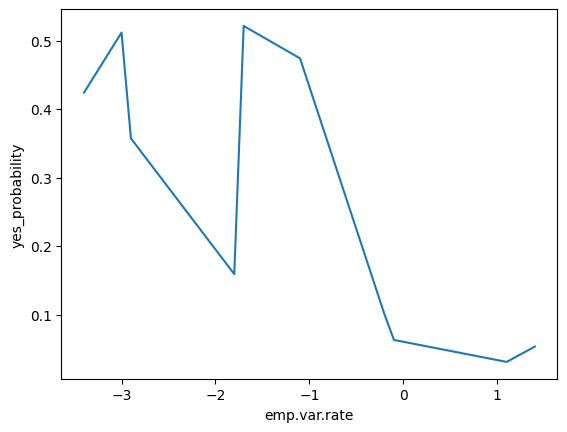

In [4]:
sns.lineplot(x=yes_prob_empvar['emp.var.rate'],y=yes_prob_empvar['yes_probability'])

In [5]:
cons_price_y = df.groupby(['cons.price.idx','y']).size().reset_index(name="count")
rates = cons_price_y['cons.price.idx'].unique()
ratios = []
for rate in rates:
    ratio = cons_price_y[cons_price_y['cons.price.idx'] == rate]
    yes_count = ratio.loc[ratio['y'] == 'yes', 'count'].sum()
    total_count = ratio['count'].sum()
    probability = yes_count / total_count
    ratios.append(probability)

yes_prob_consprice = pd.DataFrame(
    {
        "cons.price.idx" : rates,
        "yes_probability": ratios
    }
)

yes_prob_consprice[['cons.price.idx','yes_probability']].corr()

,cons.price.idx,yes_probability
cons.price.idx,1.000000,0.098161
yes_probability,0.098161,1.000000


<Axes: xlabel='cons.price.idx', ylabel='yes_probability'>

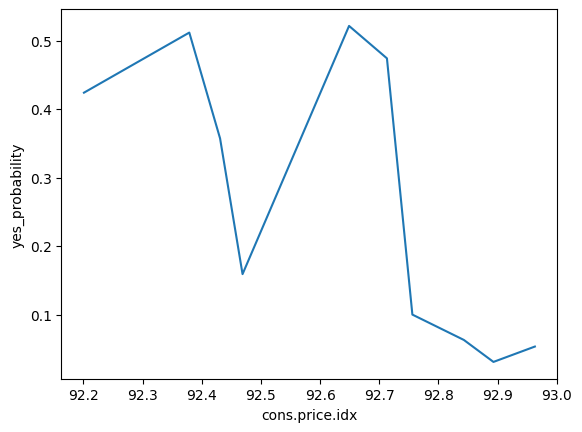

In [6]:
sns.lineplot(x=yes_prob_consprice['cons.price.idx'],y=yes_prob_empvar['yes_probability'])

In [7]:
cons_conf_y = df.groupby(['cons.conf.idx','y']).size().reset_index(name="count")
rates = cons_conf_y['cons.conf.idx'].unique()
ratios = []
for rate in rates:
    ratio = cons_conf_y[cons_conf_y['cons.conf.idx'] == rate]
    yes_count = ratio.loc[ratio['y'] == 'yes', 'count'].sum()
    total_count = ratio['count'].sum()
    probability = yes_count / total_count
    ratios.append(probability)
yes_prob_consconf = pd.DataFrame(
    {
        "cons.conf.idx" : rates,
        "yes_probability": ratios
    }
)
yes_prob_consconf[['cons.conf.idx','yes_probability']].corr()

,cons.conf.idx,yes_probability
cons.conf.idx,1.00000,0.21404
yes_probability,0.21404,1.00000


<Axes: xlabel='cons.conf.idx', ylabel='yes_probability'>

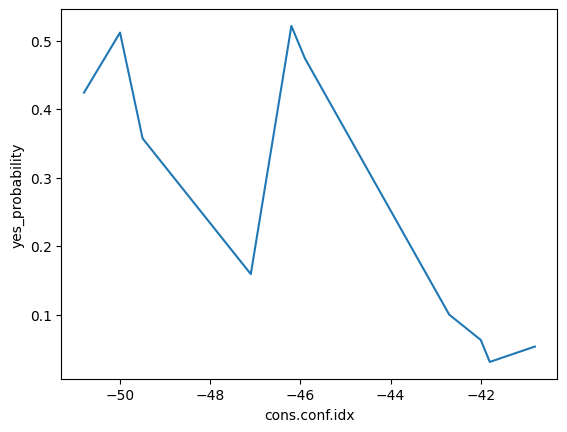

In [8]:
sns.lineplot(x=yes_prob_consconf['cons.conf.idx'],y=yes_prob_empvar['yes_probability'])

In [9]:
# outcome of previous marketing campaign poutcome: outcome of the previous marketing campaign (categorical: "failure","nonexistent","success")
poutcome_df = df.groupby(['poutcome','y']).size().reset_index(name="count")
poutcome_df

,poutcome,y,count
0,failure,no,3647
1,failure,yes,605
2,nonexistent,no,32422
3,nonexistent,yes,3141
4,success,no,479
5,success,yes,894


In [10]:
probabilities = []
for outcome in poutcome_df['poutcome'].unique():
    ratio = poutcome_df[poutcome_df['poutcome']==outcome]
    yes_count = ratio.loc[ratio['y'] == 'yes','count'].sum()
    total_count = ratio['count'].sum()
    probability = yes_count / total_count
    probabilities.append(probability)
poutcome_yes_prob = pd.DataFrame(
    {
        "poutcome":poutcome_df['poutcome'].unique(),
        "yes_probability":probabilities
    }
)
poutcome_yes_prob

,poutcome,yes_probability
0,failure,0.142286
1,nonexistent,0.088322
2,success,0.651129


<Axes: xlabel='poutcome', ylabel='yes_probability'>

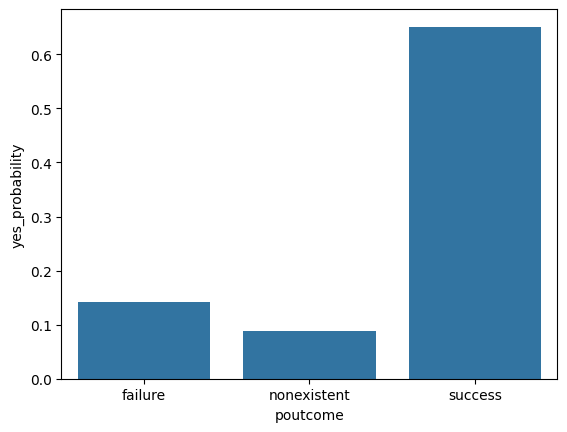

In [11]:
sns.barplot(x=poutcome_yes_prob['poutcome'],y=poutcome_yes_prob['yes_probability'])

<Axes: xlabel='pdays', ylabel='previous'>

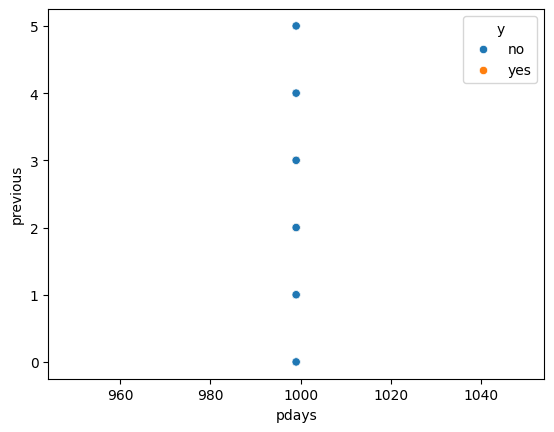

In [12]:
# pdays: number of days that passed by after the client was last contacted from a previous campaign
# previous: number of contacts performed before this campaign and for this client
df_small = df[df['pdays']==999].sample(16000)
sns.scatterplot(x=df_small['pdays'],y=df_small['previous'],hue=df_small['y'])

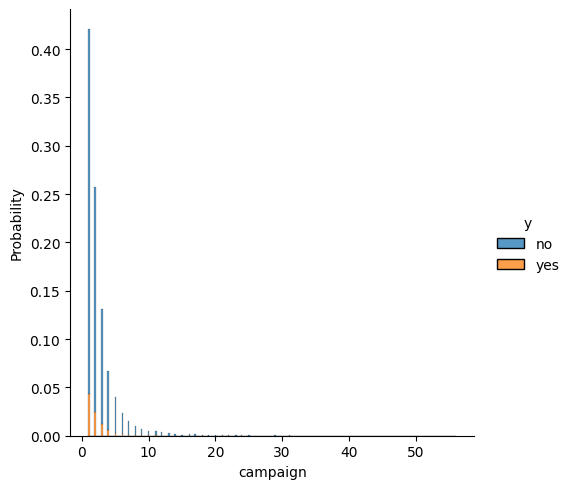

In [13]:
# campaign: number of contacts performed during this campaign and for this client 
sns.displot(x=df_small['campaign'],hue=df_small['y'],stat="probability",multiple="stack")

In [14]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx',
       'cons.conf.idx', 'euribor3m', 'nr.employed', 'y'],
      dtype='object')

In [15]:
df['job'].value_counts()

job
admin.           10422
blue-collar       9254
technician        6743
services          3969
management        2924
retired           1720
entrepreneur      1456
self-employed     1421
housemaid         1060
unemployed        1014
student            875
unknown            330
Name: count, dtype: int64

<Axes: xlabel='probability_yes', ylabel='job'>

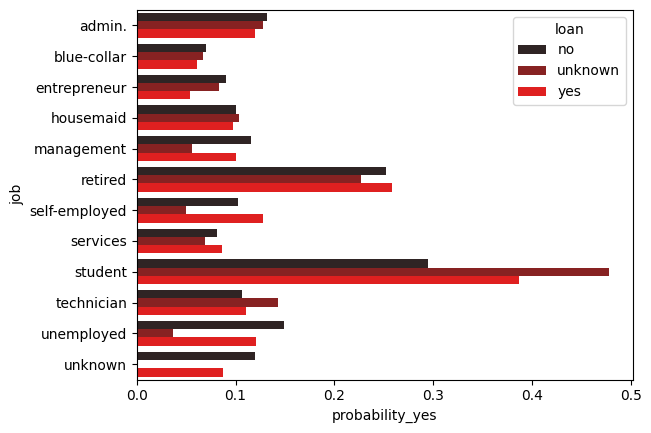

In [16]:
job_loan_probability_df = (
    df.groupby(['job','loan'])['y']
    .apply(lambda x: (x == 'yes').mean())
    .reset_index(name='probability_yes')
)
sns.barplot(data=job_loan_probability_df,x="probability_yes",y="job",hue="loan",color="r",palette='dark:r')

In [17]:
df.groupby('job')['age'].describe()

,count,mean,std,min,25%,50%,75%,max
job,,,,,,,,
admin.,10422.0,38.187296,8.907151,20.0,31.0,36.0,44.0,72.0
blue-collar,9254.0,39.555760,8.827396,20.0,33.0,39.0,46.0,80.0
entrepreneur,1456.0,41.723214,8.910840,20.0,35.0,41.0,49.0,69.0
housemaid,1060.0,45.500000,10.791220,21.0,37.0,45.0,53.0,85.0
management,2924.0,42.362859,9.303820,21.0,35.0,42.0,50.0,80.0
retired,1720.0,62.027326,10.493293,23.0,56.0,59.0,69.0,98.0
self-employed,1421.0,39.949331,9.422417,21.0,32.0,39.0,47.0,71.0
services,3969.0,37.926430,9.018749,20.0,31.0,36.0,45.0,69.0
student,875.0,25.894857,4.991334,17.0,22.0,25.0,29.0,47.0


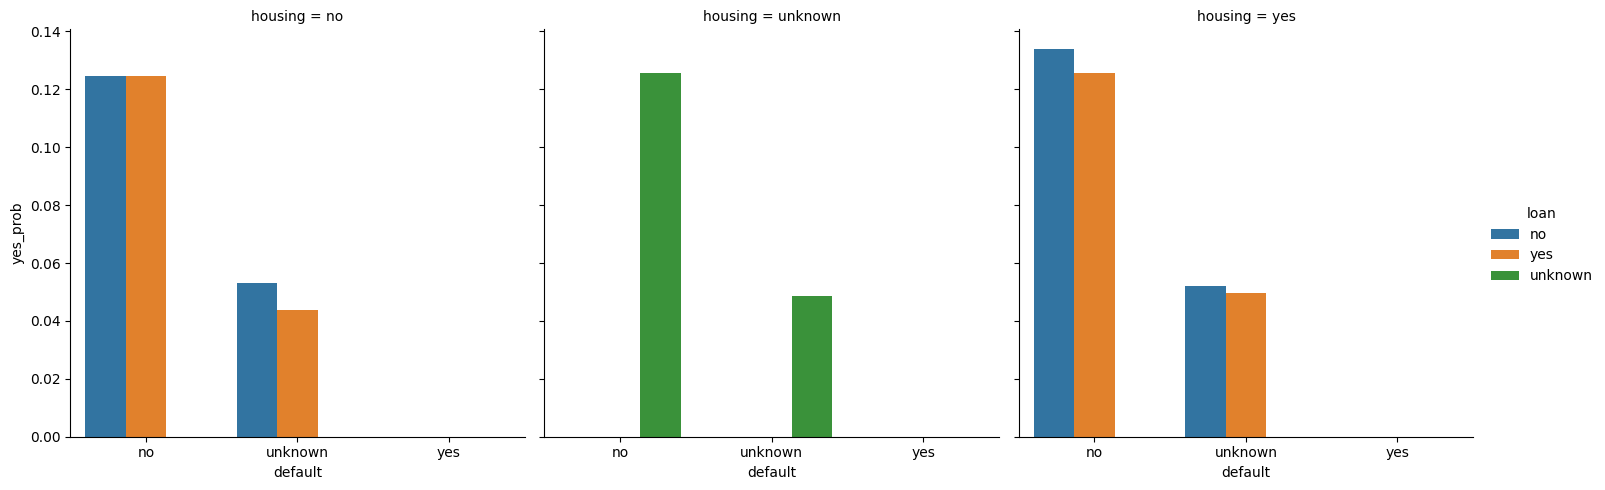

In [18]:
loan_df = df.groupby(['default','housing','loan'])['y'].apply(lambda x: (x=="yes").mean()).reset_index(name="yes_prob")
sns.catplot(data=loan_df,x="default",y="yes_prob",hue="loan",col="housing",kind="bar",height=5)

In [19]:
loan_df

,default,housing,loan,yes_prob
0,no,no,no,0.124465
1,no,no,yes,0.124502
2,no,unknown,unknown,0.125819
3,no,yes,no,0.134031
4,no,yes,yes,0.125674
5,unknown,no,no,0.052936
6,unknown,no,yes,0.043716
7,unknown,unknown,unknown,0.048458
8,unknown,yes,no,0.051909
9,unknown,yes,yes,0.049793


<Axes: xlabel='campaign', ylabel='previous'>

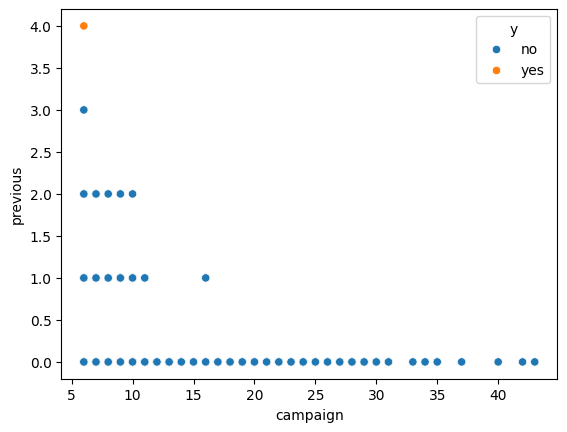

In [20]:
# number of days contacts made in this campaign and number of contacts made before this campaign
sns.scatterplot(data=df[df['campaign']>5].sample(1000),x="campaign",y="previous",hue="y")

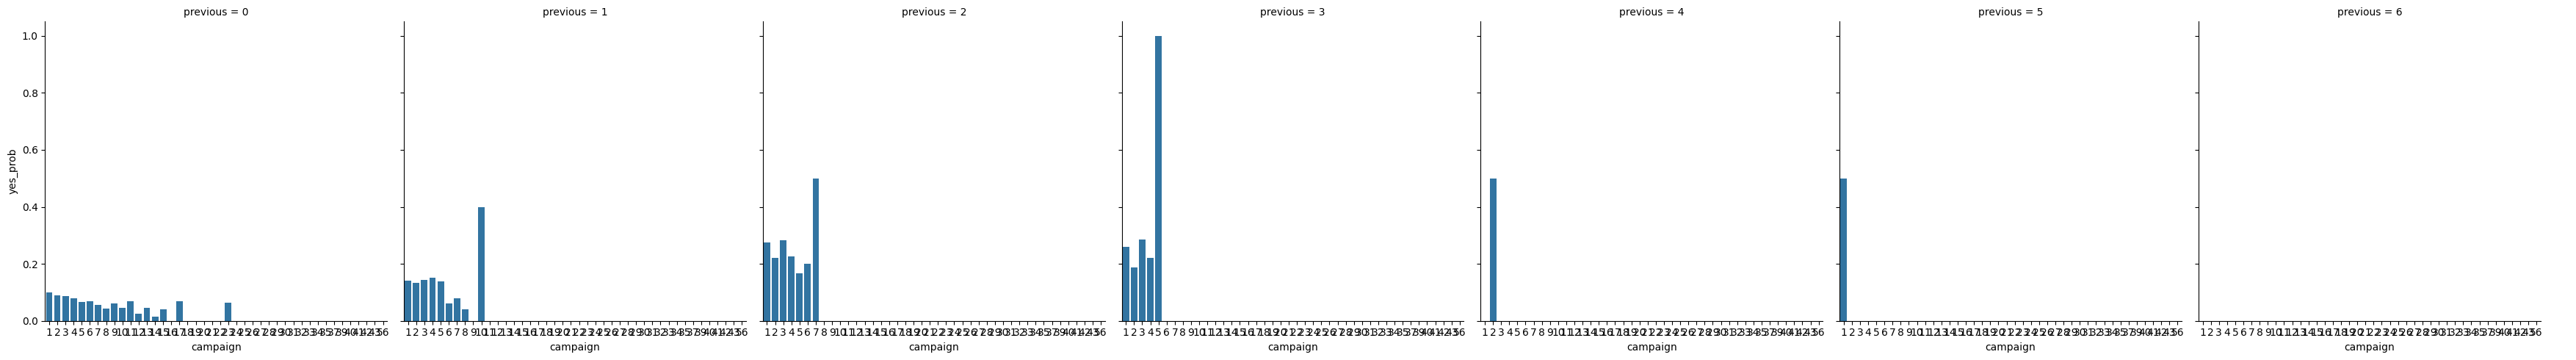

In [21]:
contacts_df_1 = (
    df.loc[df['pdays'] > 10]
    .groupby(['campaign', 'previous'])['y']
    .apply(lambda x: (x == 'yes').mean())
    .reset_index(name='yes_prob')
)
sns.catplot(data=contacts_df_1,x="campaign",y="yes_prob",col="previous",kind="bar")

<Axes: xlabel='campaign', ylabel='yes_prob'>

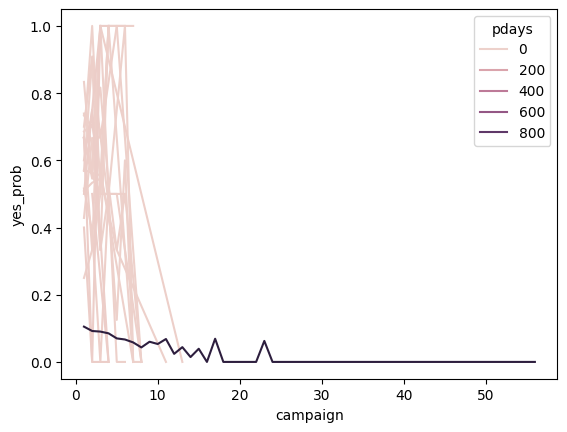

In [22]:
# number of days contacts made in this campaign and number of days passed after last contact
contacts_df_2 = df.groupby(['campaign', 'pdays'])['y'].apply(lambda x: (x == 'yes').mean()).reset_index(name='yes_prob')
sns.lineplot(data=contacts_df_2,x="campaign",y="yes_prob",hue="pdays")


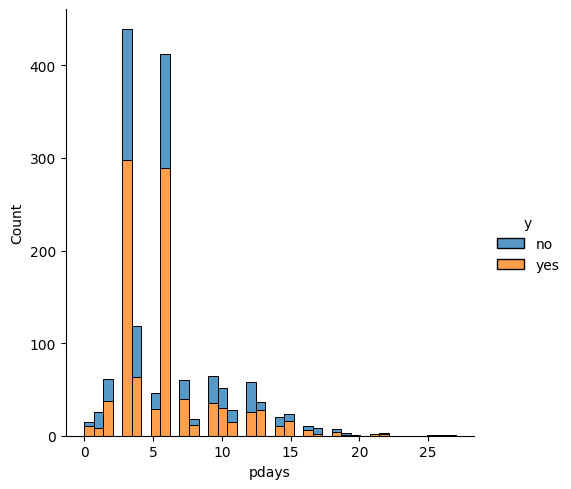

In [23]:
sns.displot(data=df[df['pdays']<999],x="pdays",hue="y",multiple="stack")

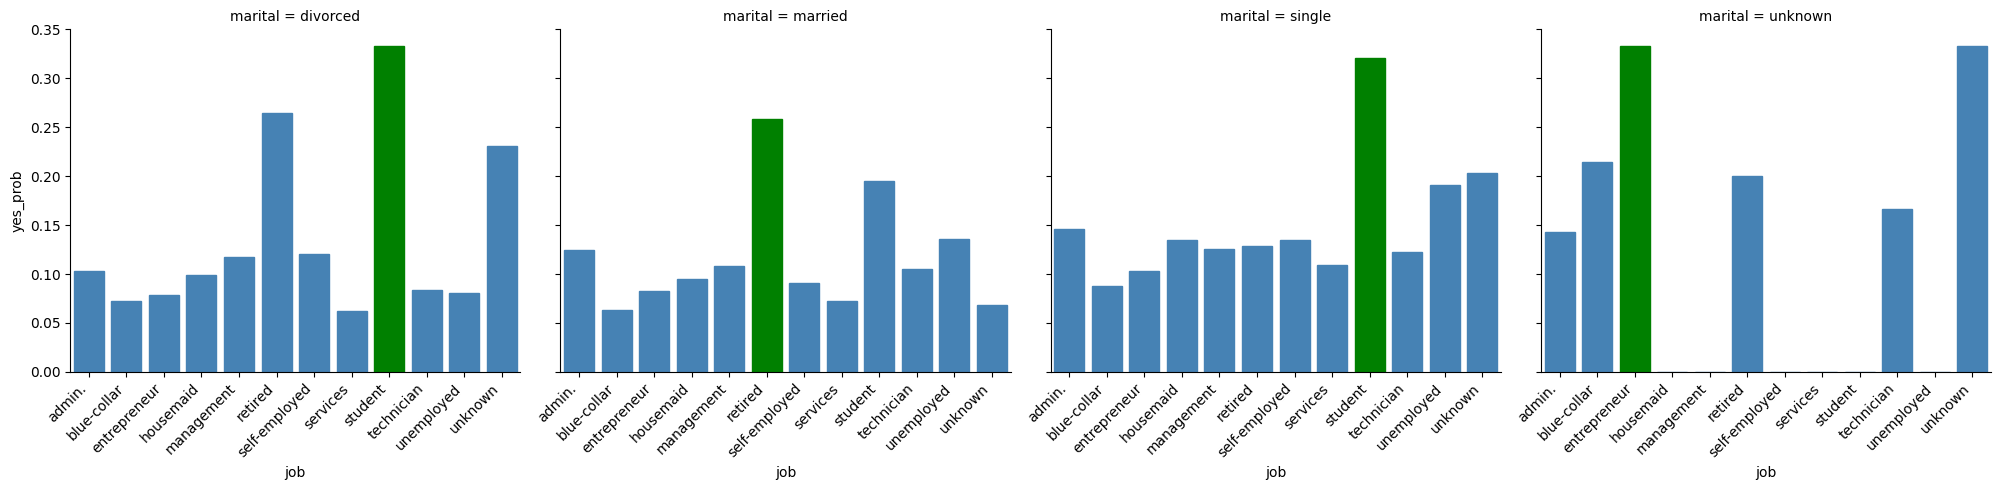

In [24]:
client_personal_df = df.groupby(['job','marital'])['y'].apply(lambda x: (x == 'yes').mean()).reset_index(name='yes_prob')
g = sns.catplot(data=client_personal_df,x="job",y="yes_prob",col="marital",kind="bar")
for ax in g.axes.flat:
    bars = ax.patches
    if bars:
        max_bar = max(bars, key=lambda bar: bar.get_height())
        for bar in bars:
            bar.set_color('green' if bar == max_bar else 'steelblue')
g.set_xticklabels(rotation=45, ha='right')
plt.tight_layout()
plt.show()

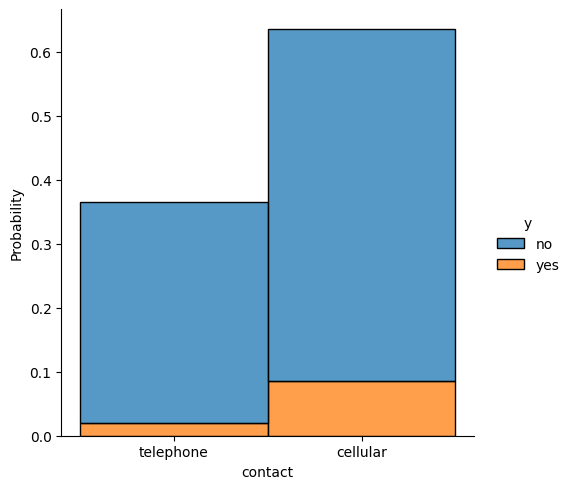

In [25]:
sns.displot(data=df.sample(1000),x="contact",hue="y",stat="probability",multiple="stack")

In [26]:
df['pdays'].describe()

count    41188.000000
mean       962.475454
std        186.910907
min          0.000000
25%        999.000000
50%        999.000000
75%        999.000000
max        999.000000
Name: pdays, dtype: float64

In [27]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx',
       'cons.conf.idx', 'euribor3m', 'nr.employed', 'y'],
      dtype='object')

In [28]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
